<div class="alert alert-block alert-info">
Singapore Management University<br>
CS105 Statistical Thinking for Data Science, 2024/25 Term 2
</div>

# CS105 Group Project Submission (Final)

-----
Provide your team details, including section, team number, team members, and the name of the dataset. 
Complete all of the following sections. For any part requiring code to derive your answers, please create a code cell immediately below your response and run the code.
To edit any markdown cell, double click the cell; after editing, execute the markdown cell to collapse it.

Include both Part I and Part II to produce a self-contained notebook. You may fine-tune Part I codes and/or findings based on feedback received on Part I submission.
<br>
-----

## Declaration

<span style="color:red">By submitting this notebook, we declare that **no part of this submission is generated by any AI tool**. We understand that AI-generated submissions will be considered as plagiarism, and just like other plagirisum cases, disciplinary actions will be imposed.</span>

#### Section: G1
#### Team: T5
#### Members:
1. Shane-Rhys Chua
2. Wong Zhi Jing 
3. Charissa Tan Shuen En
4. Ee Jing Xi
5. 

#### Dataset: credit.csv

## Part I: Exploratory Data Analysis (EDA) [8% of final grade]

In [11]:
import numpy as np 
import pandas as pd
pd.set_option('display.max_columns', None)
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

### 1. Overview of dataset [15% of Part I]

**a.** Summarise the background of the dataset [limited to 50 words]

In [34]:
data = pd.read_csv("credit.csv")

In [36]:
data.sample(5, random_state = 42)

,ID,Checking_Account,Duration,Payment_Status,Purpose,Amount,Savings_Account,Employment,Installment,Personal_Status,Guarantors,Residence_Length,Assets,Age,Credit_Rating,Existing_Credits,Housing_Type,Num_Credits,Occupation,Dependents,Telephone,Foreign_Worker,Approval
521,522,1.0,36,2,0,1842,1,2,4,2,1,4,3,34,14,3,2,1,3,1.0,2,1,0
737,738,4.0,6,2,2,4611,1,2,1,2,1,4,2,32,28,3,2,1,3,1.0,1,1,0
740,741,3.0,9,0,3,1337,1,2,4,3,1,2,3,34,13,3,2,2,4,1.0,2,1,0
660,661,4.0,12,4,2,1592,4,4,3,2,1,2,2,35,98,3,2,1,3,1.0,1,1,1
411,412,4.0,12,4,6,701,1,3,4,3,1,2,3,32,99,3,2,2,3,1.0,1,1,1


**Response.** 

The dataset contains data on 1000 borrowers and their respective credit histories, including both demographic and financial data. This provides a profile on each borrower, allowing us to analyse and predict how such variables influence the amount of loan applied for and the approval outcomes.


Overall Observation:
* `ID` is used to identify a client, we can ignore this variable.
* there are both categorical and numerical variables in this dataset.
* categorical variables are encoded to be represented by a certain numerical value.

**b.** State the size of the dataset

In [67]:
# Number of rows and columns of the dataset

rows, columns = data.shape
print(f"Number of rows: {rows}")
print(f"Number of columns: {columns}")
print(f"Total number of data points: {data.size}")

Number of rows: 1000
Number of columns: 23
Total number of data points: 23000


**Response.** 

There are a total of 23000 observations with 1000 rows and 23 columns (16 categorical variables and 7 numerical variables).

**c.** For each variable, describe what it represents and its data type (numerical or categorical)

**Response.**

|Column name|Explanation|Data type|Numerical or Categorical|
|---|---|---|---|
|ID| Identification Number | integer | Categorical | 
|Checking_Account| Status of Checking Account | float (1.0: `$0`; 2.0: <`$200`; 3.0: >=`$200`; 4.0: no checking account) | Categorical |
|Duration| Credit duration in months | integer | Numerical |
|Payment_Status| Credit history | integer (0: no credits taken; 1: all credits paid back; 2: existing credits paid back till now; 3: delay in paying off in the past; 4: critical account)| Categorical |
|Purpose| Purpose of Credit | integer (0: car (new); 1: car (used); 2: furniture/equipment; 3: radio/television; 4: domestic appliances; 5: repairs; 6: education; 7: vacation; 8: retraining; 9: business; 10: others) | Categorical |
|Amount| Credit amount | integer | Numerical | 
|Savings_Account| Status of savings account | integer (1: < `$100`; 2: `$100` - `$500`; 3: `$500` - `$1000`; 4: >`$3000`; 5: unknown/no savings account) | Categorical |
|Employment| Length of current employment | integer (1: unemployed; 2: <1 year; 3: 1 - 4 years; 4: 4 - 7 years; 5: >7 years)| Categorical |
|Installment| Installment rate as percentage of disposable income | integer | Numerical |
|Personal_Status| Marital status and sex | integer (1: male, divorced/separated; 2: male, single; 3: male, married/widowed; 4: female) | Categorical |
|Guarantors| Other debtors or guarantors | integer (1: none; 2: co-applicant; 3: guarantor) | Categorical |
|Residence_Length| Number of years staying in current residence | integer (1: < 1 year; 2: 1-2 years; 3: 2-3 years; 4: >3 years) | Categorical |
|Assets| Asset ownsership | integer (1: real estate; 2: savings agreement/life insurance (if no 1); 3: car or other (if no 1, 2); 4: unknown/none)| Categorical |
|Age| Age in years | integer | Numerical |
|Credit_Rating| Credit rating | integer | Numerical |
|Existing_Credits| Other existing credit in place | integer (1: bank; 2: stores; 3: none) | Categorical |
|Housing_Type| Type of apartment | integer (1: rent; 2: own; 3: for free) | Categorical |
|Num_Credits| Number of existing credits | integer | Numerical |
|Occupation| Occupation | integer (1 : unemployed/ unskilled - non-resident; 2 : unskilled – resident; 3 : skilled employee / official; 4 : management/ self-employed) | Categorical |
|Dependents| Number of Dependents | float | Numerical |
|Telephone| Has telephone | integer (1: none; 2: yes, registered to customer) | Categorical |
|Foreign_Worker| Whether the individual is a foreign worker or not| integer (1: yes; 2: no) | Categorical |
|Approval| Loan approval status | integer (1: approved; 0: not approved) | Categorical |

### 2. Data pre-processing [35% of Part I]

**a.** For each variable, determine the percentage of missing data. For any column with missing data, describe how you resolve the issue. Clearly state any assumption you made.

**Response.** 

In [112]:
# Calculate the percentage of valid data
percentage_missing = 1 - data.count() / rows

# Filter for columns with missing data
percentage_missing[percentage_missing > 0.0]

print(f" Number of variables with missing data: {len(percentage_missing[percentage_missing > 0.0])}")
print(f"")

# Display the variables with missing data 
missing_data_df = percentage_missing[percentage_missing > 0.0].reset_index()
missing_data_df.columns = ['Field', '% of Missing Data']

# Display the result
print(missing_data_df)

 Number of variables with missing data: 2

              Field  % of Missing Data
0  Checking_Account              0.058
1        Dependents              0.050


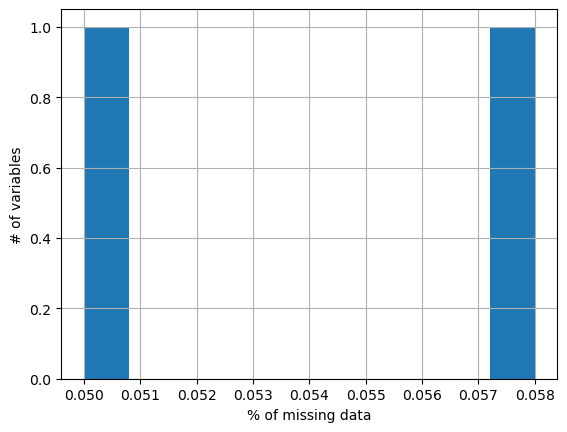

In [116]:
# Display the percentage of missing data for these 2 fields

percentage_missing[percentage_missing>0.0].hist()
plt.xlabel("% of missing data")
plt.ylabel("# of variables")
plt.show()

The percentage of missing data is insignificant compared to the amount of data we have, both variables have around `5% - 6%` of missing data.
Since we know both `Checking Account` and `Dependents` are categorical data, we will impute it with the mode category.

In [125]:
# Get the two variables and impute the missing fields with the mode

threshold = 0.10
impute_cat = percentage_missing[(percentage_missing<threshold)&(percentage_missing>0.0)].index
impute_cat_mode = list(set(impute_cat) & set(numerical_variables))
print(f"Categorical columns to impute with mode: {impute_cat_mode}\n")

for col in impute_cat_mode:
    data[col].fillna(data[col].mode().iloc[0], inplace=True)

# confirm no missing values

print(f"After imputation: ")
print(data[impute_cat_mode].count())

Categorical columns to impute with mode: ['Checking_Account', 'Dependents']

After imputation: 
Checking_Account    1000
Dependents          1000
dtype: int64


**b.** For each variable, identify outliers (if any) and describe how you resolve the issue. Clearly state any assumption you made.

**Response.** 

**c.** For categorical variables, perform the necessary encoding.

**Response.** 

### 3.	Exploratory analysis and visualization [50% of Part I]

**a.** For each variable, provide relevant summary statistics

**Response.** 

**b.** For each variable, provide an appropriate visualisation depicting the distribution of its values, and summarize any key observation(s) you made.

**Response.** 

**c.** Perform bi-variate analysis on the variables. You do not need to present the analysis of every pair of variables; only focus on the pairs you believe are worth investigating and explain. For each pair, describe the relationship between the two variables. Use appropriate statistical methods and/or visualizations.

**Response.** 

## Part II: Modeling [12% of final grade]

### 1. Problem formulation [15% of Part II]

**a.** Formulate one regression problem and one classification based on the dataset, in **no more than 50 words**.

**Response.** 

**b.** State which problem (regression or classification) you would be investigating and why, in **no more than 20 words**.

**Response.** 

**c.** Clearly specify the dependent variable you are predicting, and its significance, in **no more than 20 words**

**Response.** 

### 2. Model training [30% of Part II]

**a.** Perform feature selection. For each variable, decide if you want to include it as a feature and provide a justification. You may leverage on your analysis in Part I: EDA and/or perform additional analysis.

**Response.** 

**b.** Split the dataset into train and test sets. Describe how you split step by step.

**Response.** 

**c.** State the model(s) you will train, and explain your choice(s), in **no more than 50 words per model**. You only need to
train one model, but if you do train more models, limit yourself to no more than three---Grading is based on the validity and soundness of your model, rather than the quantity.

**Response.** 

**d.** For each model, perform the training, and report the trained parameters and the training scores, if applicable. 

**Response.** 

### 3. Model evaluation and selection [30% of Part II]

**a.** For each model, predict the response variable on the test set.

**Response.** 

**b.** Describe the metric you use to evaluate your model(s). Report the test scores for each model.

**Response.** 

**c.** If you trained more than one model, identify the final model you would choose for the prediction task, and explain your choice, **in no more than 50 words**.

**Response.** 

### 4. Findings and conclusion [20% of Part II]

**a.** Interpret what your model is implying, and summarize any insight you have drawn from the project. Explain if it is consistent with intuition, and if not, provide a plausible justification. Limit your entire response to **50 words**.

**Response.** 

**b.** Share any lesson you have learned from the project, in **no more than 50 words**.

**Response.** 

### 5. Non-technical protocol [5% of Part II]

**a.** Describe the detailed contribution of each team member, including both the tangible (e.g., implementation, testing, writing) and intangible (e.g., generating ideas, planning, leadership) efforts.

**Response.** 

**b.** List any references and sources you have cited.

**Response.** 